In [71]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from statistics import mean


class BacktestCrossMA:
    def __init__(self) -> None:
        self.df = pd.DataFrame()
        self.days = []
        self.trades = []

    def load_data(self, path):
        self.df = pd.read_csv(path)
        self.df["date"] = pd.to_datetime(self.df["date"], unit="ms")
        self.df = self.df.set_index(self.df["date"])
        del self.df["date"]

    def populate_indicators(self):
        self.df['ma100'] = self.df['close'].rolling(100).mean()
        self.df['ma200'] = self.df['close'].rolling(200).mean()

    def populate_signals(self):
        self.df['buy_signal'] = False
        self.df['sell_signal'] = False
        self.df.loc[(self.df['ma100'] > self.df['ma200']), 'buy_signal'] = True
        self.df.loc[(self.df['ma100'] < self.df['ma200']), 'sell_signal'] = True

    def run_backtest(self):
        balance = 1000
        position = None
        asset = "BTC"
        fee = 0.001  # 0.1% fee
        self.days = []
        self.trades = []
        previous_day = -1

        for index, row in self.df.iterrows():
            
            current_day = index.day
            if previous_day != current_day:
                temp_balance = balance
                if position:
                    close_price = row['close']
                    trade_result = (close_price - position['open_price']) / position['open_price']
                    close_size = (position['open_size'] + position['open_size'] * trade_result)
                    fees = close_size * fee
                    close_size = close_size - fees
                    temp_balance = temp_balance + close_size - position['open_size']
                self.days.append({
                    'day':index.date(),
                    'balance':temp_balance,
                    'price':row['close']
                })
                previous_day = current_day
            

            if position is None and row['buy_signal']:
                open_price = row['close']
                open_size = balance
                fees = open_size * fee
                open_size = open_size - fee
                balance = balance - fees
                stop_loss = open_price - 0.1*open_price
                position = {
                    'open_price': open_price,
                    'open_size': balance,
                    'open_date': index,
                    'open_fee': fees,
                    'open_reason': 'Market Buy',
                    'open_balance': balance,
                    'stop_loss': stop_loss,
                }

                # print(f"{index} - Buy for {balance}$ of {asset} at {open_price}$, fees: {fees}$")

            elif position and row['low'] <= position['stop_loss']:
                close_price = position['stop_loss']
                trade_result = (close_price - position['open_price']) / position['open_price']
                close_size = position['open_size'] + position['open_size'] * trade_result
                fees = close_size * fee
                close_size = close_size - fees
                balance = balance + close_size - position['open_size']
                self.trades.append({
                    'open_date': position['open_date'],
                    'close_date': index,
                    'open_price': position['open_price'],
                    'close_price': close_price,
                    'open_size': position['open_size'],
                    'close_size': close_size,
                    'open_fee': fees,
                    'open_reason': position['open_reason'],
                    'close_reason': 'Stop Loss',
                    'open_balance': position['open_balance'],
                    'close_balance': balance,
                })
                position = None                
            

            elif position and row['sell_signal']:
                close_price = row['close']
                trade_result = (close_price - position['open_price']) / position['open_price']
                close_size = position['open_size'] + position['open_size'] * trade_result
                fees = close_size * fee
                close_size = close_size - fees
                balance = balance + close_size - position['open_size']
                self.trades.append({
                    'open_date': position['open_date'],
                    'close_date': index,
                    'open_price': position['open_price'],
                    'close_price': close_price,
                    'open_size': position['open_size'],
                    'close_size': close_size,
                    'open_fee': fees,
                    'open_reason': position['open_reason'],
                    'close_reason': 'Market Sell',
                    'open_balance': position['open_balance'],
                    'close_balance': balance,
                })
                position = None
                # print(f"{index} - Sell for {balance}$ of {asset} at {close_price}$, fees: {fees}$")      
            
        
        print(f"Final balance: {balance}$")
        
    def backtest_analysis(self):
        df_days = pd.DataFrame(self.days)
        df_trades = pd.DataFrame(self.trades)
        
        if df_days.empty:
            raise ValueError('No days found')
        
        if df_trades.empty:
            raise ValueError('No trades found')
        
        df_days['evolution'] = df_days['balance'].diff() 
        df_days['daily_returns'] = df_days['balance'].pct_change()
        
        df_trades['trade_result'] = df_trades['close_size'] - df_trades['open_size']
        df_trades['trade_result_pct'] = (df_trades['trade_result'] / df_trades['open_size'])
        df_trades['trades_duration'] = df_trades['close_date'] - df_trades['open_date']
        
        df_days['balance_ath'] = df_days['balance'].cummax()
        df_days['drawdown'] = df_days['balance_ath'] - df_days['balance']
        df_days['drawdown_pct'] = df_days['drawdown'] / df_days['balance_ath']
        
        self.df_days = df_days
        
        total_trades = len(df_trades)
        total_days = len(df_days)
        
        good_trades = df_trades.loc[df_trades['trade_result'] > 0]
        total_good_trades = len(good_trades)
        avg_profit_good_trades = good_trades['trade_result_pct'].mean()
        mean_good_trades_duration = good_trades['trades_duration'].mean()
        global_win_rate = total_good_trades / total_trades
        
        bad_trades = df_trades.loc[df_trades['trade_result'] < 0]
        total_bad_trades = len(bad_trades)
        avg_profir_bad_trades = bad_trades['trade_result_pct'].mean()
        mean_bad_trades_duration = bad_trades['trades_duration'].mean()
        
        max_days_drawdown = df_days['drawdown_pct'].max()
        initial_balance = df_days.iloc[0]['balance']
        final_balance = df_days.iloc[-1]['balance']
        balance_evolution = (final_balance - initial_balance) / initial_balance
        mean_trades_duration = df_trades['trades_duration'].mean()
        avg_profit = df_trades['trade_result_pct'].mean()
        mean_trades_per_days = total_trades/total_days
        
        best_trade = df_trades.loc[df_trades['trade_result_pct'].idxmax()]
        worst_trade = df_trades.loc[df_trades['trade_result_pct'].idxmin()]
        
        sharpe_ratio = (365**(1/2) * df_days['daily_returns'].mean())/df_days['daily_returns'].std()
        
        print(f'Period: [{df_days.iloc[0]['day']}] -> [{df_days.iloc[-1]['day']}]')
        print(f'Initial balance: {round(initial_balance,2)} $')
        
        print(f'\n--- General Information ---')
        print(f'Final balance: {round(final_balance,2)} $')
        print(f'Performance: {round(balance_evolution * 100,2)} %')
        print(f'Worst Drawdawn: -{round(max_days_drawdown*100,2)} %')
        print(f'Total trades on the period: {total_trades} ')
        print(f'Averae Profit: {round(avg_profit*100,2)} %') 
        print(f'Global Win Rate: {round(global_win_rate*100,2)} %')
        print(f'Sharpe Ratio {round(sharpe_ratio,2)} %')
        
        print(f'\n--- General Information ---')
        print(f'Mean Trades per day: {round(mean_trades_per_days,2)}')
        print(f'Mean Trades Duration : {mean_trades_duration}')
        print(f'Best trades:  {round(best_trade['trade_result_pct']*100,2)} % the {best_trade['open_date']} -> {best_trade['close_date']}')
        print(f'Worst trades:  {round(worst_trade['trade_result_pct']*100,2)} % the {worst_trade['open_date']} -> {worst_trade['close_date']}')
        print(f'Total Good trades on the period:  {total_good_trades}')
        print(f'Total Bad trades on the period:  {total_bad_trades}')  
        print(f'Average Good Trades results:  {round(avg_profit_good_trades*100,2)} %')  
        print(f'Average Bad Trades results:  {round(avg_profir_bad_trades*100,2)} %') 
        print(f'Mean Good Trades Duration:  {mean_good_trades_duration}')  
        print(f'Mean Bad Trades Duration:  {mean_bad_trades_duration}')
        
        
        print(f'\n--- Trades reasons ---')
        print(df_trades['open_reason'].value_counts().to_string())
        print(df_trades['close_reason'].value_counts().to_string())
        
     
        
    def plot_equity_vs_asset(self):
        df_days = self.df_days.copy()
        df_days = df_days.set_index('day')
        ig, ax_left = plt.subplots(figsize=(15,20), nrows=4, ncols=1)

        ax_left[0].title.set_text('Profit and Loss curve')
        ax_left[0].plot(df_days['balance'], color='royalblue', lw=1)
        ax_left[0].fill_between(df_days['balance'].index, df_days['balance'], alpha=0.2, color='royalblue')
        ax_left[0].axhline(y=df_days.iloc[0]['balance'], color='black', alpha=0.3)
        ax_left[0].legend(['Wallet evolution (equity)'], loc='upper left')
            
        ax_left[1].title.set_text('Asset evolution')
        ax_left[1].plot(df_days['price'], color='sandybrown', lw=1)
        ax_left[1].fill_between(df_days['price'].index, df_days['balance'], alpha=0.2, color='sandybrown')
        ax_left[1].axhline(y=df_days.iloc[0]['price'], color='black', alpha=0.3)
        ax_left[1].legend(['Asset evolution'], loc='upper left') 
            
        ax_left[2].title.set_text('Drawdown Curve')
        ax_left[2].plot(-df_days['drawdown_pct']*100, color='indianred', lw=1)
        ax_left[2].fill_between(df_days['drawdown_pct'].index, -df_days['drawdown_pct']*100, alpha=0.2, color='indianred')
        ax_left[2].axhline(y=0, color='black', alpha=0.3)
        ax_left[2].legend(['Drawdown in %'], loc='lower left')
        
        ax_right = ax_left[3].twinx()
        
        ax_left[3].title.set_text('P&L VS Asset (not on the same scale)')
        ax_left[3].plot(df_days['balance'], color='royalblue', lw=1)
        ax_right.plot(df_days['price'], color='sandybrown', lw=1)
        ax_left[3].legend(['Wallet evolution (equity)'], loc ='lower right')
        ax_right.legend(['Asset evolution'], loc='upper left')
        
        plt.show()
        
        return df_days 

        
        
        
        
    
    
        
        


Final balance: 6377.288347114146$
Period: [2017-08-17] -> [2023-07-03]
Initial balance: 1000.0 $

--- General Information ---
Final balance: 6381.22 $
Performance: 538.12 %
Worst Drawdawn: -62.39 %
Total trades on the period: 166 
Averae Profit: 1.97 %
Global Win Rate: 41.57 %
Sharpe Ratio 0.85 %

--- General Information ---
Mean Trades per day: 0.08
Mean Trades Duration : 6 days 17:55:18.072000
Best trades:  94.99 % the 2017-11-16 21:00:00 -> 2017-12-21 21:00:00
Worst trades:  -10.09 % the 2020-03-05 14:00:00 -> 2020-03-08 23:00:00
Total Good trades on the period:  69
Total Bad trades on the period:  97
Average Good Trades results:  11.33 %
Average Bad Trades results:  -4.68 %
Mean Good Trades Duration:  10 days 09:35:39.130000
Mean Bad Trades Duration:  4 days 03:33:24.123000

--- Trades reasons ---
open_reason
Market Buy    166
close_reason
Market Sell    142
Stop Loss       24


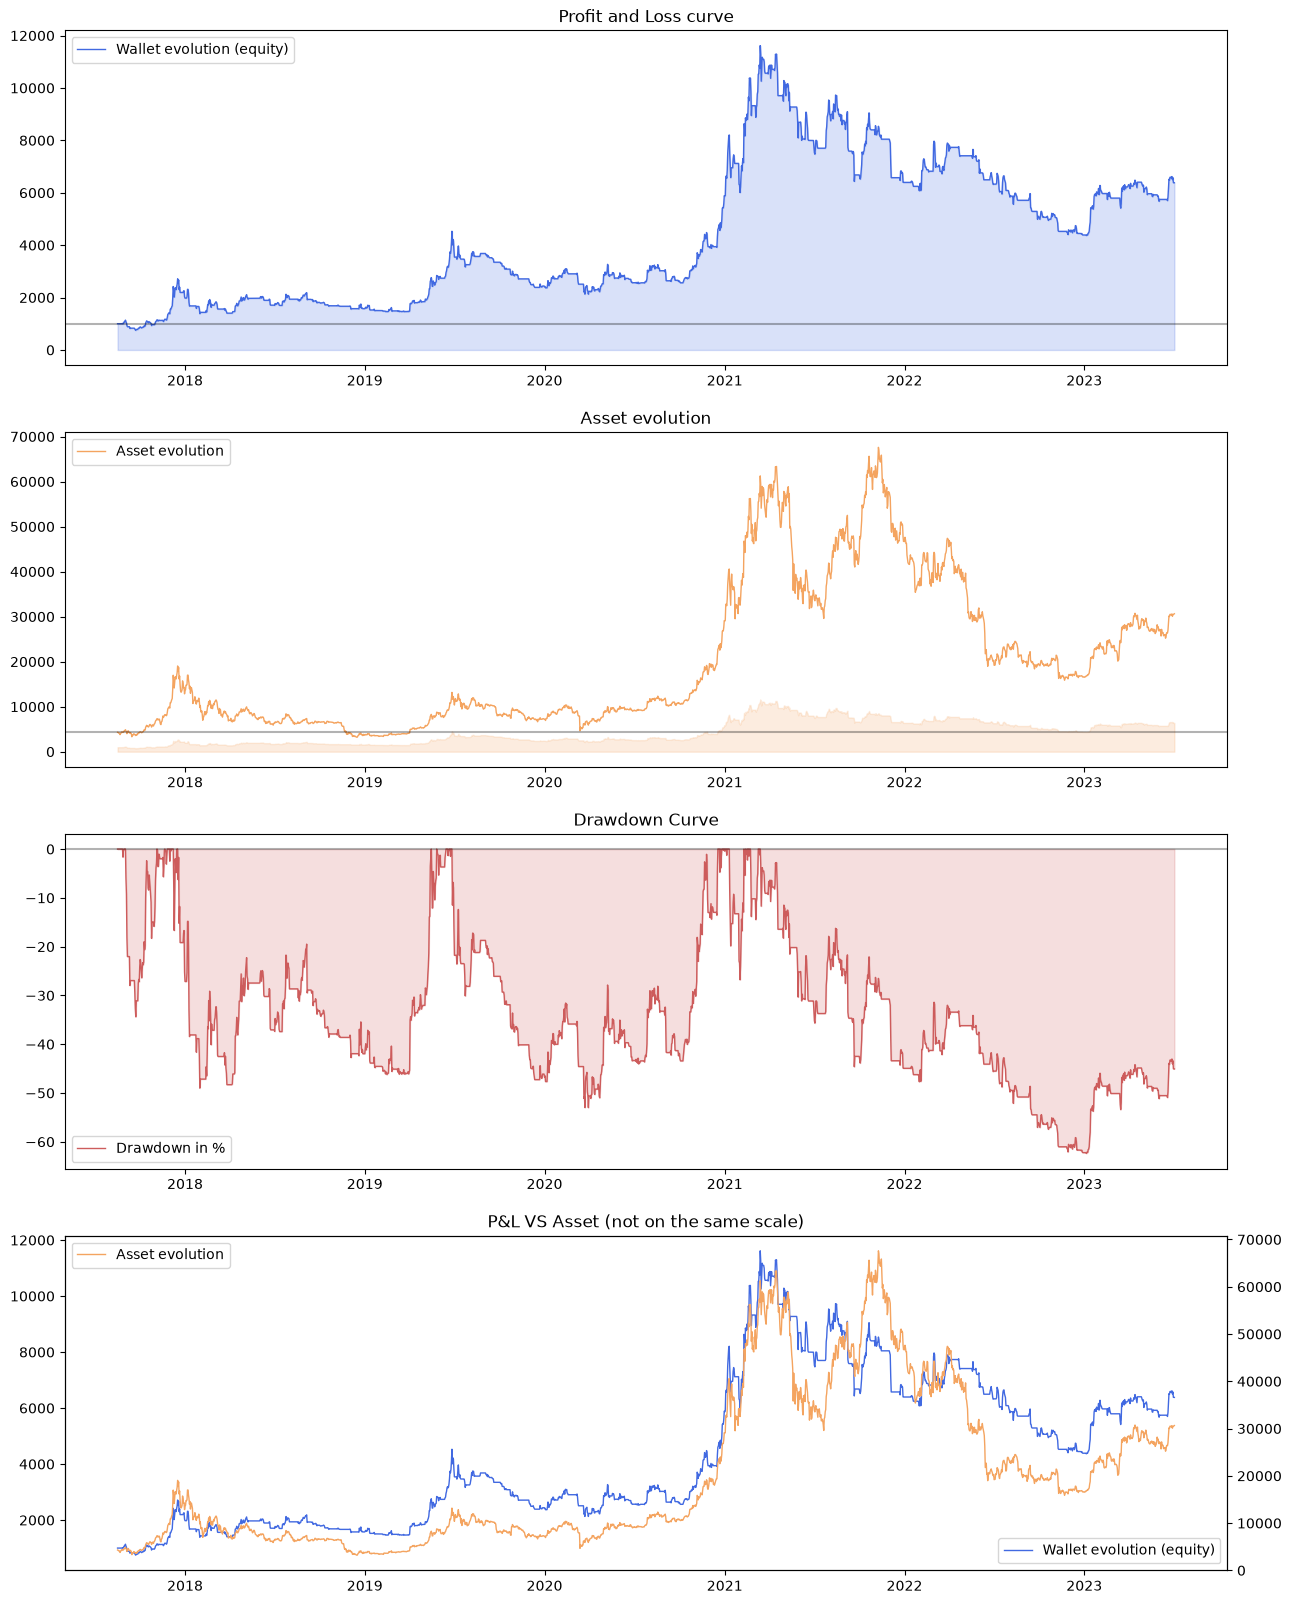

,balance,price,evolution,daily_returns,balance_ath,drawdown,drawdown_pct
day,,,,,,,
2017-08-17,1000.000000,4308.83,NaN,NaN,1000.000000,0.000000,0.000000
2017-08-18,1000.000000,4286.53,0.000000,0.000000,1000.000000,0.000000,0.000000
2017-08-19,1000.000000,4163.49,0.000000,0.000000,1000.000000,0.000000,0.000000
2017-08-20,1000.000000,4086.09,0.000000,0.000000,1000.000000,0.000000,0.000000
2017-08-21,1000.000000,4108.28,0.000000,0.000000,1000.000000,0.000000,0.000000
...,...,...,...,...,...,...,...
2023-06-29,6502.714589,30079.99,-115.442679,-0.017443,11616.554663,5113.840074,0.440220
2023-06-30,6575.643162,30441.34,72.928574,0.011215,11616.554663,5040.911501,0.433942
2023-07-01,6383.672019,30469.83,-191.971143,-0.029194,11616.554663,5232.882644,0.450468


In [73]:
bt = BacktestCrossMA()
bt.load_data('BTC-USDT.csv')
bt.populate_indicators()
bt.populate_signals()
bt.run_backtest()
bt.backtest_analysis()
bt.plot_equity_vs_asset()

In [74]:
# bt.plot_equity_vs_asset()

In [75]:
pd.DataFrame(bt.days)

,day,balance,price
0,2017-08-17,1000.000000,4308.83
1,2017-08-18,1000.000000,4286.53
2,2017-08-19,1000.000000,4163.49
3,2017-08-20,1000.000000,4086.09
4,2017-08-21,1000.000000,4108.28
...,...,...,...
2142,2023-06-29,6502.714589,30079.99
2143,2023-06-30,6575.643162,30441.34
2144,2023-07-01,6383.672019,30469.83
2145,2023-07-02,6383.672019,30575.77


In [76]:
pd.DataFrame(bt.trades)

,open_date,close_date,open_price,close_price,open_size,close_size,open_fee,open_reason,close_reason,open_balance,close_balance
0,2017-08-26 01:00:00,2017-09-05 01:00:00,4284.00,3855.60,999.000000,898.200900,0.899100,Market Buy,Stop Loss,999.000000,898.200900
1,2017-09-05 02:00:00,2017-09-05 06:00:00,4054.11,4013.46,897.302699,887.417264,0.888306,Market Buy,Market Sell,897.302699,887.417264
2,2017-09-10 00:00:00,2017-09-10 06:00:00,4239.00,3815.10,886.529846,797.078985,0.797877,Market Buy,Stop Loss,886.529846,797.078985
3,2017-09-10 07:00:00,2017-09-11 04:00:00,3988.95,4169.02,796.281906,831.395599,0.832228,Market Buy,Market Sell,796.281906,831.395599
4,2017-09-20 06:00:00,2017-09-22 11:00:00,3950.00,3555.00,830.564204,746.760276,0.747508,Market Buy,Stop Loss,830.564204,746.760276
...,...,...,...,...,...,...,...,...,...,...,...
161,2023-05-06 14:00:00,2023-05-09 12:00:00,28606.61,27758.34,6152.992272,5964.567443,5.970538,Market Buy,Market Sell,6152.992272,5964.567443
162,2023-05-18 04:00:00,2023-05-21 01:00:00,27302.62,27158.79,5958.602875,5921.285787,5.927213,Market Buy,Market Sell,5958.602875,5921.285787
163,2023-05-29 08:00:00,2023-06-03 11:00:00,27900.61,27129.79,5915.364501,5746.186699,5.751939,Market Buy,Market Sell,5915.364501,5746.186699
164,2023-06-18 09:00:00,2023-06-29 21:00:00,26527.34,30417.34,5740.440513,6575.643162,6.582225,Market Buy,Market Sell,5740.440513,6575.643162
